In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [7]:
ratings = pd.read_csv(filepath_or_buffer='../data/ml-1m/ratings.dat'  ,sep='::', engine='python', names=['user', 'item', 'rating', 'ts'])
ratings

,user,item,rating,ts
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291
...,...,...,...,...
1000204,6040,1091,1,956716541
1000205,6040,1094,5,956704887
1000206,6040,562,5,956704746
1000207,6040,1096,4,956715648


#### Shape

In [10]:
n_users = ratings['user'].nunique()
n_items = ratings['item'].nunique()
n_ratings = len(ratings)
print(n_users, n_items, n_ratings)

6040 3706 1000209


### Sparsity

In [11]:
print(1 - n_ratings / (n_users * n_items))

0.9553163743776871


### Ratings distribution

In [20]:
ratings_distr = ratings['rating'].value_counts().sort_index()

<BarContainer object of 5 artists>

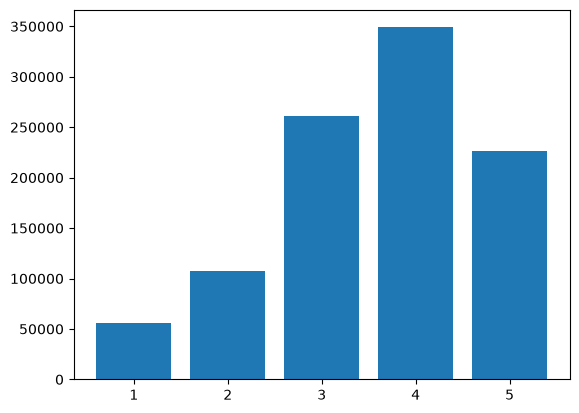

In [25]:
plt.bar(ratings_distr.index, ratings_distr.values)

#### Threshold = 4: the histogram shows most ratings fall on 3-4, so r ≥ 4 keeps the clearly liked items without making positives too scarce.

### Action per user and film

In [26]:
ratings.groupby('user').size()

user
1        53
2       129
3        51
4        21
5       198
       ... 
6036    888
6037    202
6038     20
6039    123
6040    341
Length: 6040, dtype: int64

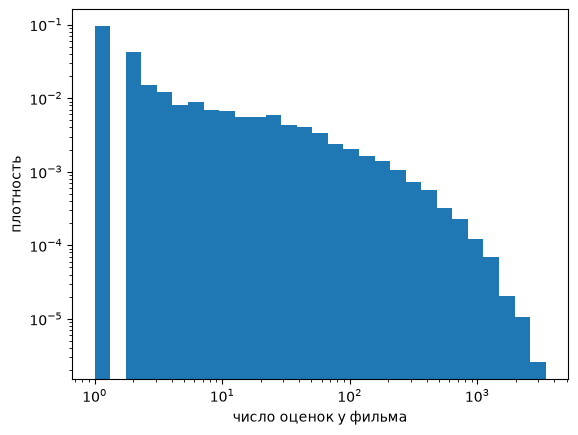

In [30]:
counts = ratings.groupby('item').size()
bins = np.logspace(np.log10(counts.min()), np.log10(counts.max()), 30)
plt.hist(counts, bins=bins, density=True)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('число оценок у фильма')
plt.ylabel('плотность')
plt.show()

#### The plot shows us, that the majority of films have small amount of ratings, while big amount of ratings have very very small part of films

### Dates

In [31]:
dates = pd.to_datetime(ratings['ts'], unit='s')

In [32]:
dates.dt.year.value_counts().sort_index()

ts
2000    904757
2001     68058
2002     24046
2003      3348
Name: count, dtype: int64

#### Dates distribution makes us use leave-last-out split

In [33]:
pos = ratings[ratings['rating'] >= 4]
item_counts = pos.groupby('item').size()
user_counts = pos.groupby('user').size()
print((item_counts < 5).sum(), (user_counts < 5).sum())

408 4


In [34]:
rare = item_counts[item_counts < 5]
print(rare.sum() / item_counts.sum())

0.0015574997262207512


#### min_interactions = 5: removes 408 items (~11% of items, but <1% of positive interactions) and 4 users; rare items cannot get meaningful embeddings and would appear in test without train history.